In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [5]:
# ---------------------------------------------------------
# 1. Load the dataset
# ---------------------------------------------------------

FILE_PATH = "School_Data_CSV.csv"
OUTPUT_DIR = Path("school_visualisations")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(FILE_PATH, dtype={"new_long": "string"}, encoding="latin1")

initial_rows = len(df)
print(f"Initial records: {initial_rows:,}")

Initial records: 199,853


C:\Users\jorda\AppData\Local\Temp\ipykernel_22140\457822390.py:9: DtypeWarning: Columns (0: emisno) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(FILE_PATH, dtype={"new_long": "string"}, encoding="latin1")


In [6]:
# ---------------------------------------------------------
# 2. Prepare and clean the data
# ---------------------------------------------------------

# Remove exact duplicate rows.
df = df.drop_duplicates().copy()
print(f"Exact duplicate rows removed: {initial_rows - len(df):,}")
print(f"Records remaining: {len(df):,}")

# Convert coordinates to numeric; invalid text becomes NaN.
df["new_long"] = pd.to_numeric(df["new_long"], errors="coerce")
df["new_lat"] = pd.to_numeric(df["new_lat"], errors="coerce")

# South African bounding box: longitude 16–33° E,
# latitude -35–-22° S. This is a broad plausibility check.
valid_coordinates = (
    df["new_long"].between(16, 33)
    & df["new_lat"].between(-35, -22)
)

missing_or_invalid_coordinates = ~valid_coordinates
print(
    "Records with missing, non-numeric or implausible coordinates: "
    f"{missing_or_invalid_coordinates.sum():,}"
)

# Clean quintile labels by standardising text and mapping
# recognised variants to quintiles 1–5.
df["quintile_clean"] = (
    df["quintile"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.replace(r"\s+", "", regex=True)
)

quintile_map = {
    "1": "1", "Q1": "1", "NQ1": "1",
    "2": "2", "Q2": "2", "NQ2": "2",
    "3": "3", "Q3": "3", "NQ3": "3",
    "4": "4", "Q4": "4", "NQ4": "4",
    "5": "5", "Q5": "5", "NQ5": "5",
}

df["quintile_clean"] = df["quintile_clean"].map(quintile_map)

invalid_quintile = df["quintile_clean"].isna()
print(f"Records with missing or unrecognised quintiles: "
      f"{invalid_quintile.sum():,}")

# Treat blank, placeholder and invalid ward identifiers as unusable.
df["ward_clean"] = (
    df["ward_id"]
    .astype("string")
    .str.strip()
)

invalid_wards = (
    df["ward_clean"].isna()
    | df["ward_clean"].eq("")
    | df["ward_clean"].str.upper().isin(
        ["TO BE UPDATED", "99", ".", "UNKNOWN", "NOT APPLICABLE"]
    )
)

print(f"Records with missing or placeholder ward IDs: "
      f"{invalid_wards.sum():,}")

# Keep separate datasets for each plot so one plot's requirements
# do not unnecessarily remove records from the other plots.
plot_df = df.loc[~invalid_quintile].copy()
ward_df = plot_df.loc[~invalid_wards].copy()
coordinate_df = df.loc[valid_coordinates].copy()

print(f"Records available for quintile plots: {len(plot_df):,}")
print(f"Records available for ward analysis: {len(ward_df):,}")
print(f"Records available for geographic plot: {len(coordinate_df):,}")

# Count rows, not unique emisno values. Repeated emisno values can
# have different wards or quintiles, so deduplicating by emisno
# would require an arbitrary rule for choosing a single record.


Exact duplicate rows removed: 788
Records remaining: 199,065
Records with missing, non-numeric or implausible coordinates: 115,444
Records with missing or unrecognised quintiles: 41,890
Records with missing or placeholder ward IDs: 19,950
Records available for quintile plots: 157,175
Records available for ward analysis: 152,014
Records available for geographic plot: 83,619


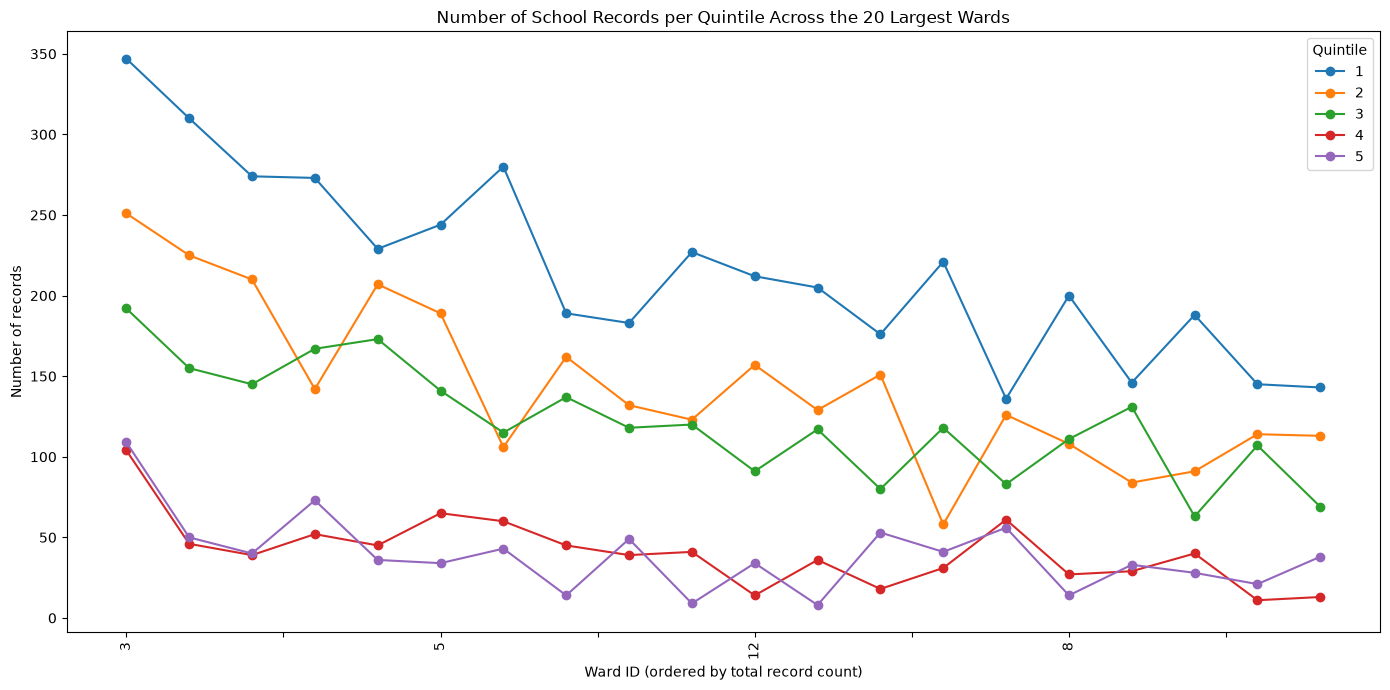

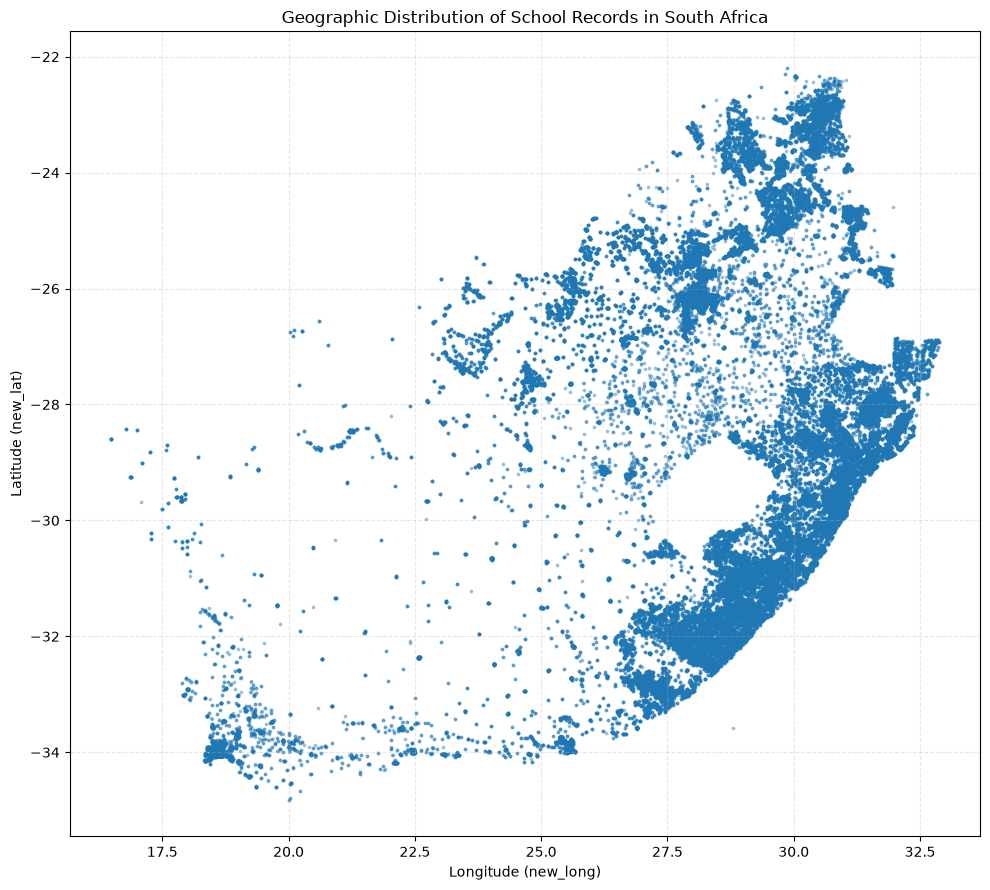

In [7]:
# ---------------------------------------------------------
# 3(a). Line plot: number of school records per quintile
#      across wards
# ---------------------------------------------------------

# A line plot suggests continuity or order between wards, which
# may not exist. There are thousands of wards, so display only the
# 20 wards with the most valid records to keep the plot readable.
top_wards = (
    ward_df["ward_clean"]
    .value_counts()
    .head(20)
    .index
)

top_ward_df = ward_df[ward_df["ward_clean"].isin(top_wards)]

ward_quintile_counts = (
    top_ward_df
    .groupby(["ward_clean", "quintile_clean"])
    .size()
    .unstack(fill_value=0)
)

# Use a consistent quintile order.
quintile_order = ["1", "2", "3", "4", "5"]
ward_quintile_counts = ward_quintile_counts.reindex(
    columns=quintile_order, fill_value=0
)

# Sort wards by total record count for easier comparison.
ward_quintile_counts = ward_quintile_counts.loc[
    ward_quintile_counts.sum(axis=1).sort_values(ascending=False).index
]

ax = ward_quintile_counts.plot(
    kind="line",
    marker="o",
    figsize=(14, 7),
    linewidth=1.5
)

ax.set_title("Number of School Records per Quintile Across the 20 Largest Wards")
ax.set_xlabel("Ward ID (ordered by total record count)")
ax.set_ylabel("Number of records")
ax.legend(title="Quintile")
ax.tick_params(axis="x", labelrotation=90)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "a_schools_per_quintile_by_ward.png", dpi=300)
plt.show()
plt.close()


# ---------------------------------------------------------
# 3(b). Scatter plot: geographic locations of schools
# ---------------------------------------------------------

plt.figure(figsize=(10, 9))
plt.scatter(
    coordinate_df["new_long"],
    coordinate_df["new_lat"],
    s=3,
    alpha=0.35
)

plt.title("Geographic Distribution of School Records in South Africa")
plt.xlabel("Longitude (new_long)")
plt.ylabel("Latitude (new_lat)")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "b_school_geographic_locations.png", dpi=300)
plt.show()
plt.close()


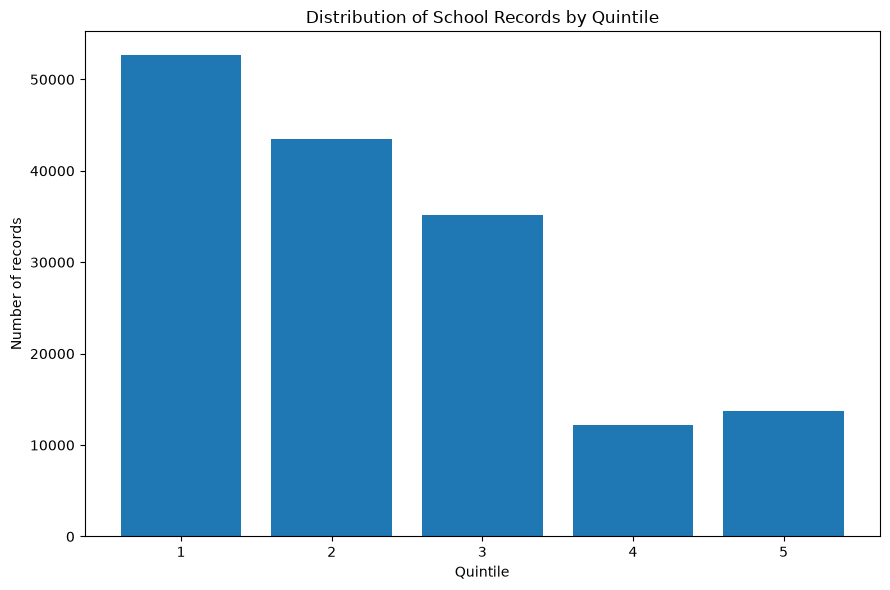


All figures saved in: C:\Users\jorda\Desktop\Question7_GenAI_Comparison\school_visualisations


In [8]:
# ---------------------------------------------------------
# 3(c). Histogram: distribution of schools by quintile
# ---------------------------------------------------------

# Quintile is categorical, not continuous. A bar chart is usually
# more appropriate than a histogram, so use a bar chart of counts
# for the five cleaned categories instead.
quintile_counts = (
    plot_df["quintile_clean"]
    .value_counts()
    .reindex(quintile_order, fill_value=0)
)

plt.figure(figsize=(9, 6))
plt.bar(quintile_counts.index, quintile_counts.values)

plt.title("Distribution of School Records by Quintile")
plt.xlabel("Quintile")
plt.ylabel("Number of records")
plt.xticks(quintile_order)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "c_school_records_by_quintile.png", dpi=300)
plt.show()
plt.close()

print(f"\nAll figures saved in: {OUTPUT_DIR.resolve()}")